# 04 · Usando o modelo para decidir

Quem toma decisão olha para municípios e escolas, não para um aluno de cada vez. Neste
notebook juntamos as previsões por município e respondemos às perguntas do desafio:

1. Quais fatores mais impactam a alfabetização?
2. Quais municípios apresentam maior risco educacional?
3. Como prever municípios que podem não atingir metas futuras?
4. Quais regiões possuem padrões semelhantes?
5. Quais variáveis possuem maior influência nos modelos?

In [1]:
import sys
import json
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import config as C

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
resultados = json.loads((C.DIR_REPORTS / "metricas.json").read_text(encoding="utf-8"))

def figura(nome, largura=800):
    display(Image(filename=str(C.DIR_IMAGENS / f"{nome}.png"), width=largura))

## 1. Do aluno ao município

Se fizermos a média das probabilidades dos alunos de uma cidade, temos uma previsão da
taxa de alfabetização daquela cidade. Nos municípios de teste, que o modelo nunca viu,
dá para comparar com a taxa real.

Municípios de teste: 1,101
Erro absoluto médio: 8.5 p.p.
Correlação previsto × observado: 0.81


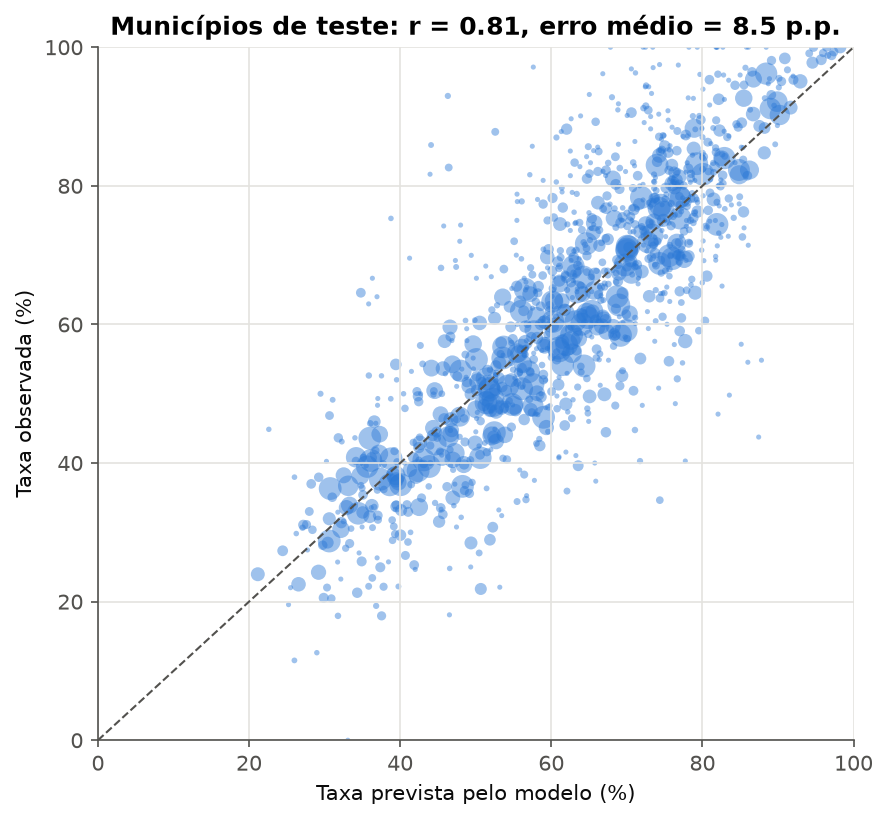

In [2]:
agregado = resultados["municipal_agregado_teste"]
print(f"Municípios de teste: {agregado['municipios']:,}")
print(f"Erro absoluto médio: {agregado['mae_pp']:.1f} p.p.")
print(f"Correlação previsto × observado: {agregado['correlacao']:.2f}")
figura("aplicacao_previsto_vs_observado", 550)

Aqui o modelo vai bem: correlação de 0,81 com a taxa real e erro médio de 8,5 pontos.
Ele não consegue separar alunos da mesma turma, mas ordena bem os municípios. Antes de
incluir os dados das escolas do Inep, esses números eram 0,79 e 9,0.

## 2. Quem não vai bater a meta?

Testamos dois jeitos, nos mesmos municípios de teste de 2024:

a) Pela taxa prevista. Pegamos a taxa prevista da rede municipal e comparamos com a
   meta. Como o modelo erra em média uns 11,5 pontos, transformamos a distância até a
   meta numa probabilidade, levando esse erro em conta.

b) Um classificador direto, com uma linha por município, treinado para prever "não
   atingiu a meta de 2024".

In [3]:
meta = resultados["municipal_meta"]
print(f"Municípios que não atingiram a meta em {C.ANO_ALVO}: {meta['pct_nao_atingiu_meta']:.1%}")
print(f"Erro típico da taxa prevista no teste: {meta['sigma_pp']:.1f} p.p.\n")
colunas = ["roc_auc", "pr_auc", "precisao", "recall", "f1", "brier"]
pd.DataFrame({
    "a) pela taxa prevista": meta["via_taxa_prevista_teste"],
    f"b) classificador direto ({meta['classificador_direto_escolhido']})": meta["classificador_direto_teste"],
}).T[colunas]

Municípios que não atingiram a meta em 2024: 46.7%
Erro típico da taxa prevista no teste: 11.5 p.p.



,roc_auc,pr_auc,precisao,recall,f1,brier
a) pela taxa prevista,0.81,0.79,0.73,0.66,0.69,0.18
b) classificador direto (XGBoost),0.83,0.81,0.74,0.69,0.72,0.17


In [4]:
print("Distância entre a meta e a taxa do ano anterior:")
print(f"  meta 2024 − taxa 2023: {meta['gap_meta_vs_ant_2024'][0]:+.1f} a {meta['gap_meta_vs_ant_2024'][1]:+.1f} p.p.")
print(f"  meta 2025 − taxa 2024: {meta['gap_meta_vs_ant_2025'][0]:+.1f} a {meta['gap_meta_vs_ant_2025'][1]:+.1f} p.p.")

Distância entre a meta e a taxa do ano anterior:
  meta 2024 − taxa 2023: -32.0 a +7.2 p.p.
  meta 2025 − taxa 2024: -76.3 a +68.9 p.p.


Os dois acertam de forma parecida em 2024 (AUC de 0,81 e 0,82). O classificador
direto vai um pouco melhor porque aprendeu com a meta de 2024. Mas é justamente isso
que impede de usá-lo em 2025: a meta de 2024 ficava no máximo 7 pontos acima da taxa
anterior, e a de 2025 chega a 69 pontos acima. O modelo nunca viu nada parecido e
daria uma probabilidade moderada para cidades que precisariam dobrar a taxa em um ano.

Por isso usamos o caminho (a) na projeção. Ele separa a previsão (a taxa) da meta, e
funciona para qualquer meta futura, até 2030.

## 3. Projeção para 2025

Treinamos o modelo de novo com todos os dados de 2024 e usamos 2024 como "ano anterior"
para prever 2025. Depois comparamos a taxa prevista com a meta de 2025 de cada
município.

Um cuidado com o Rio Grande do Sul: o estado caiu quase 19 pontos em 2024. Se o modelo
repetisse em 2025 o efeito "ser do RS" que aprendeu em 2024, a queda seria contada
duas vezes. Então tiramos esse efeito na projeção e marcamos os municípios do RS com um
alerta (`alerta_quebra_serie`).

In [5]:
risco = pd.read_csv(C.DIR_REPORTS / f"risco_municipios_{C.ANO_PROJECAO}.csv")
proj = resultados["projecao"]
print(f"Municípios projetados: {proj['municipios']:,}")
print(f"Taxa prevista abaixo da meta: {proj['pct_previstos_abaixo_meta']:.1%}")
print("Faixas de risco (chance de não atingir a meta):")
ordem = ["Muito alto", "Alto", "Moderado", "Baixo"]
risco["faixa_risco"].value_counts().reindex(ordem).to_frame("municípios")

Municípios projetados: 5,352
Taxa prevista abaixo da meta: 51.8%
Faixas de risco (chance de não atingir a meta):


,municípios
faixa_risco,
Muito alto,1198
Alto,1012
Moderado,1176
Baixo,1966


In [6]:
risco["variacao_prevista"] = risco["taxa_prevista"] - risco[f"taxa_{C.ANO_ALVO}"]
risco.groupby(pd.qcut(risco[f"taxa_{C.ANO_ALVO}"], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]),
              observed=True)[[f"taxa_{C.ANO_ALVO}", "taxa_prevista", "variacao_prevista"]].mean()

,taxa_2024,taxa_prevista,variacao_prevista
taxa_2024,,,
Q1,35.02,42.62,7.60
Q2,52.02,56.66,4.64
Q3,64.14,66.30,2.16
Q4,75.16,73.91,-1.25
Q5,88.96,82.11,-6.84


A projeção leva em conta a regressão à média que vimos na análise exploratória: os
municípios mais baixos tendem a subir, e os mais altos, a cair um pouco. Um ranking
que só repetisse o ano anterior erraria nisso.

In [7]:
risco[~risco["alerta_quebra_serie"]].head(20)

,id_municipio,nome_municipio,sigla_uf,nome_regiao,taxa_2024,taxa_prevista,meta_taxa_ano,gap_previsto,prob_nao_atingir_meta,faixa_risco,alerta_quebra_serie,variacao_prevista
3,2411502,Santo Antônio,RN,Nordeste,23.56,31.64,70.80,39.16,1.00,Muito alto,False,8.08
12,3505401,Barra do Turvo,SP,Sudeste,34.89,45.74,80.00,34.26,1.00,Muito alto,False,10.85
15,1302553,Manaquiri,AM,Norte,20.56,23.81,57.70,33.89,1.00,Muito alto,False,3.25
17,1720150,São Félix do Tocantins,TO,Norte,61.90,46.58,80.00,33.42,1.00,Muito alto,False,-15.32
18,1300060,Amaturá,AM,Norte,64.58,34.89,68.27,33.38,1.00,Muito alto,False,-29.69
25,2509057,Marcação,PB,Nordeste,24.23,39.99,72.42,32.43,1.00,Muito alto,False,15.76
27,2100808,Anapurus,MA,Nordeste,34.63,48.09,80.00,31.91,1.00,Muito alto,False,13.46
28,2512788,Riacho de Santo Antônio,PB,Nordeste,55.56,47.09,78.99,31.90,1.00,Muito alto,False,-8.47
29,1713601,Monte do Carmo,TO,Norte,19.71,41.28,73.10,31.82,1.00,Muito alto,False,21.57
30,2107456,Olinda Nova do Maranhão,MA,Nordeste,37.64,48.23,80.00,31.77,1.00,Muito alto,False,10.59


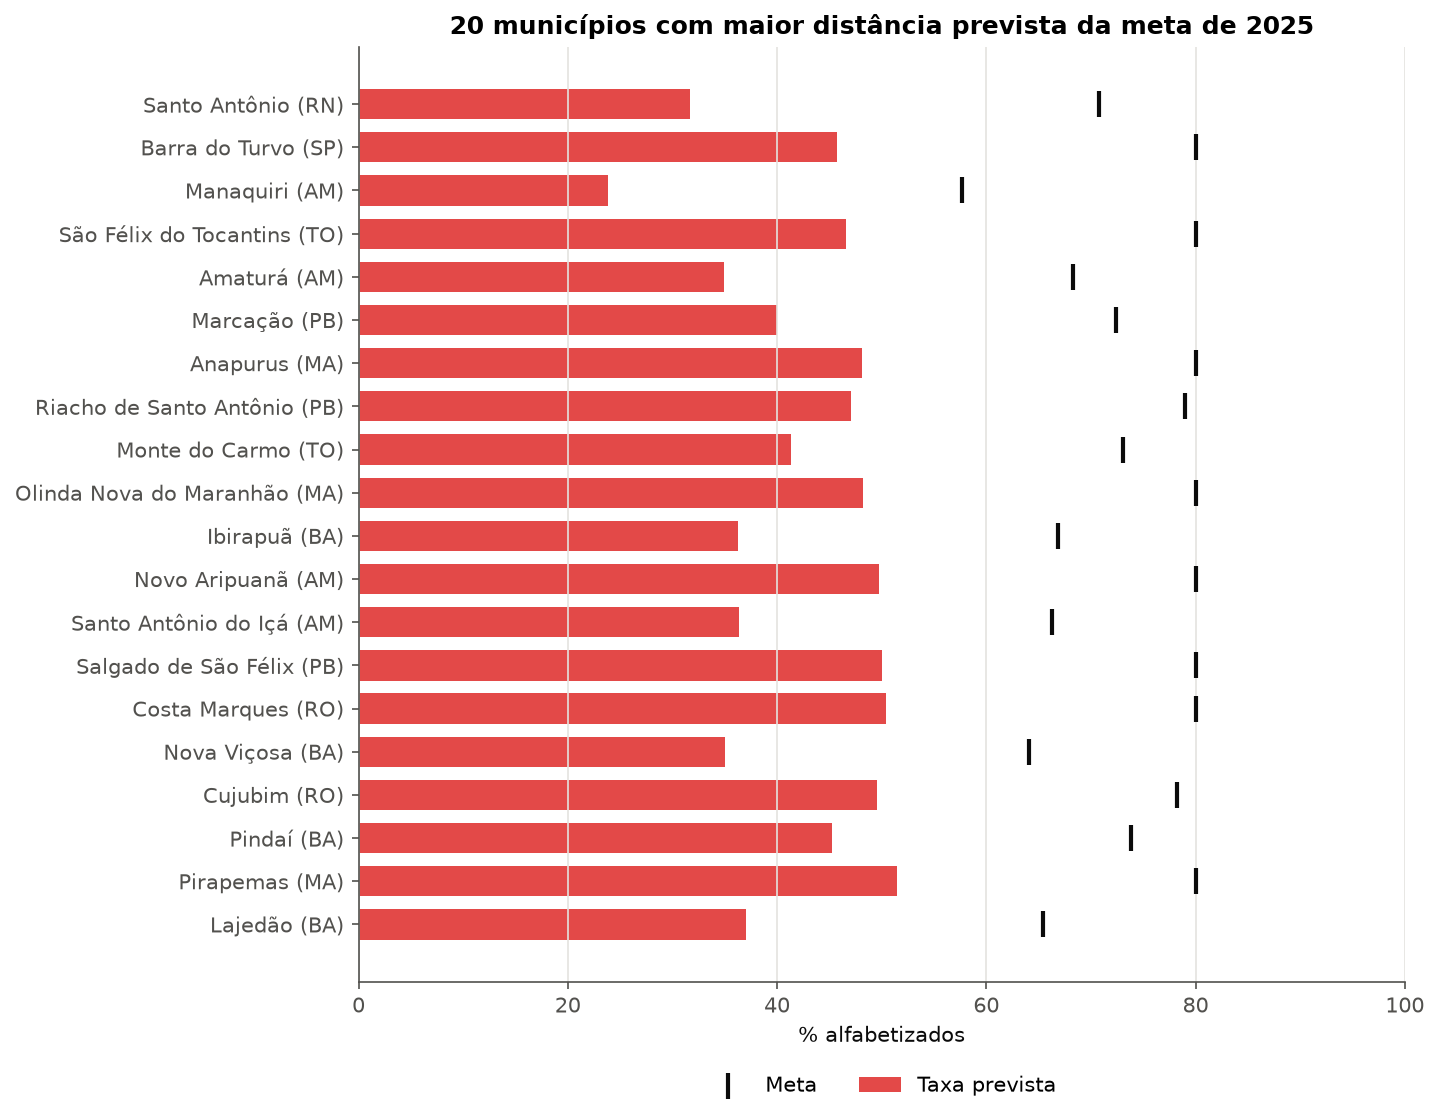

In [8]:
figura("aplicacao_ranking_risco", 750)

In [9]:
risco["alto"] = risco["faixa_risco"].isin(["Alto", "Muito alto"])
por_uf = (risco.groupby("sigla_uf")
          .agg(municipios=("id_municipio", "size"), risco_alto=("alto", "sum"),
               prob_media=("prob_nao_atingir_meta", "mean"))
          .assign(pct_risco_alto=lambda d: 100 * d["risco_alto"] / d["municipios"])
          .sort_values("pct_risco_alto", ascending=False))
por_uf.head(12)

,municipios,risco_alto,prob_media,pct_risco_alto
sigla_uf,,,,
RS,441,408,0.88,92.52
AM,55,50,0.83,90.91
BA,398,354,0.80,88.94
PA,142,118,0.75,83.10
AP,16,12,0.70,75.00
AC,22,16,0.72,72.73
RO,52,37,0.69,71.15
RJ,92,60,0.64,65.22
SE,75,45,0.61,60.00


Em proporção, Amazonas, Bahia, Pará, Amapá, Acre e Rondônia têm mais
municípios em risco alto. O RS também aparece no topo, mas com ressalva: ainda não dá
para saber se a queda de 2024 vai se repetir.

Conferimos também se os dados de 2024 se parecem com os de 2023, porque a projeção
supõe que o que valia de um ano para o outro continua valendo. Para isso usamos o PSI
(visto em aula): acima de 0,1 a variável mudou o bastante para pedir atenção.

In [10]:
proj = resultados["projecao"]
print(f"Maior PSI entre as variáveis: {proj['psi_max']:.3f}")
pd.Series(proj["psi_features_instaveis"], name="PSI").sort_values(ascending=False).to_frame()

Maior PSI entre as variáveis: 0.157


,PSI
mun_taxa_municipal_ant,0.16
mun_media_ant,0.14
mun_taxa_publica_ant,0.13


Nenhuma variável mudou muito (PSI acima de 0,25). As taxas municipais mudaram um pouco
(PSI de 0,13 a 0,16), o que é normal de um ano para o outro.
A projeção dá para usar, lembrando que ela se baseia num único par de anos.

## 4. Municípios parecidos (agrupamento)

Usamos o K-Means para agrupar os municípios pelo perfil: resultado, variação, participação,
diferença entre escolas e contexto socioeconômico. O número de grupos foi escolhido
olhando a silhueta e o gráfico do cotovelo.

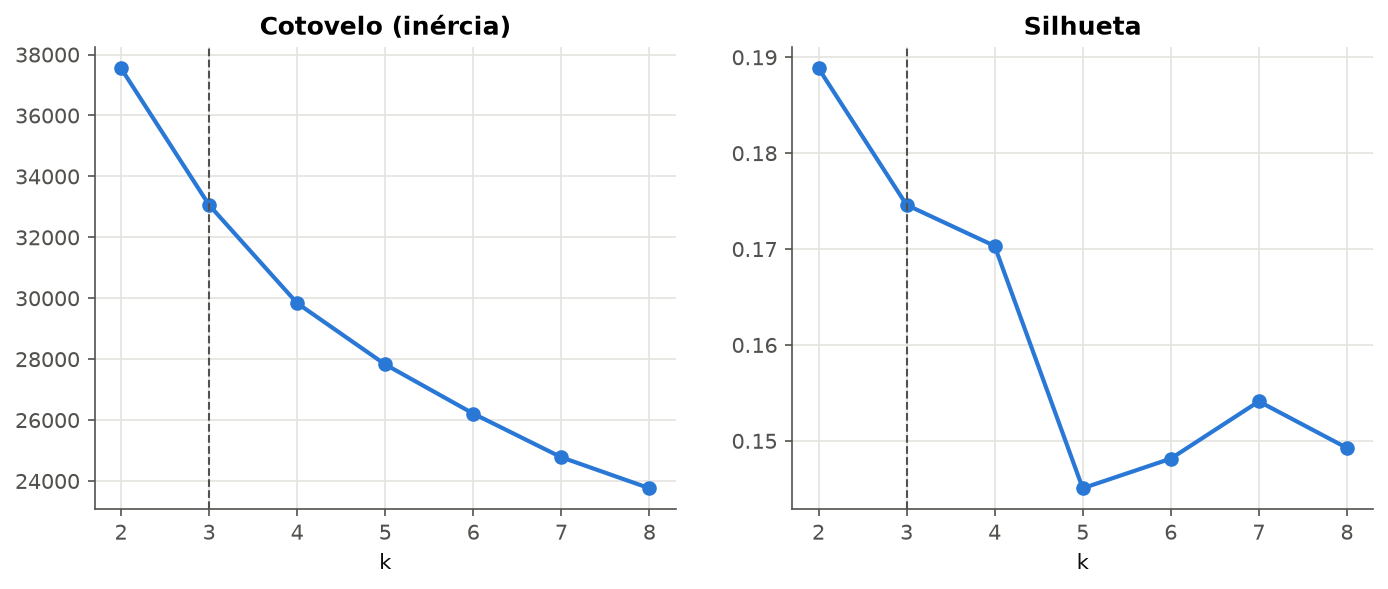

,k,inercia,silhueta,davies_bouldin
0,2,"37,551.05",0.19,1.89
1,3,"33,062.20",0.17,1.96
2,4,"29,838.94",0.17,1.77
3,5,"27,826.54",0.15,1.78
4,6,"26,212.78",0.15,1.73
5,7,"24,778.88",0.15,1.77
6,8,"23,762.32",0.15,1.75


In [11]:
figura("cluster_escolha_k", 850)
pd.DataFrame(resultados["clusters"]["escolha_k"])

In [12]:
perfil = pd.read_csv(C.DIR_REPORTS / "perfil_clusters.csv", index_col=0)
perfil

,perfil,municipios,taxa_atual,variacao_pp,mun_participacao_ant,desvio_taxa_escolas_ant,taxa_alfab_adultos,pib_per_capita,pct_urbana,pct_esgoto_adequado,densidade
cluster,,,,,,,,,,,
0,Alto analfabetismo adulto e pouca infraestrutura,1868,55.82,2.94,92.43,16.28,79.47,"11,884.28",57.03,15.92,23.15
1,Interior pouco povoado e de renda mais alta,1569,66.70,-0.66,89.34,13.93,92.02,"38,421.84",65.47,5.76,12.73
2,Urbano com infraestrutura,1795,67.83,4.35,90.18,14.33,94.44,"32,418.37",89.63,78.53,49.65


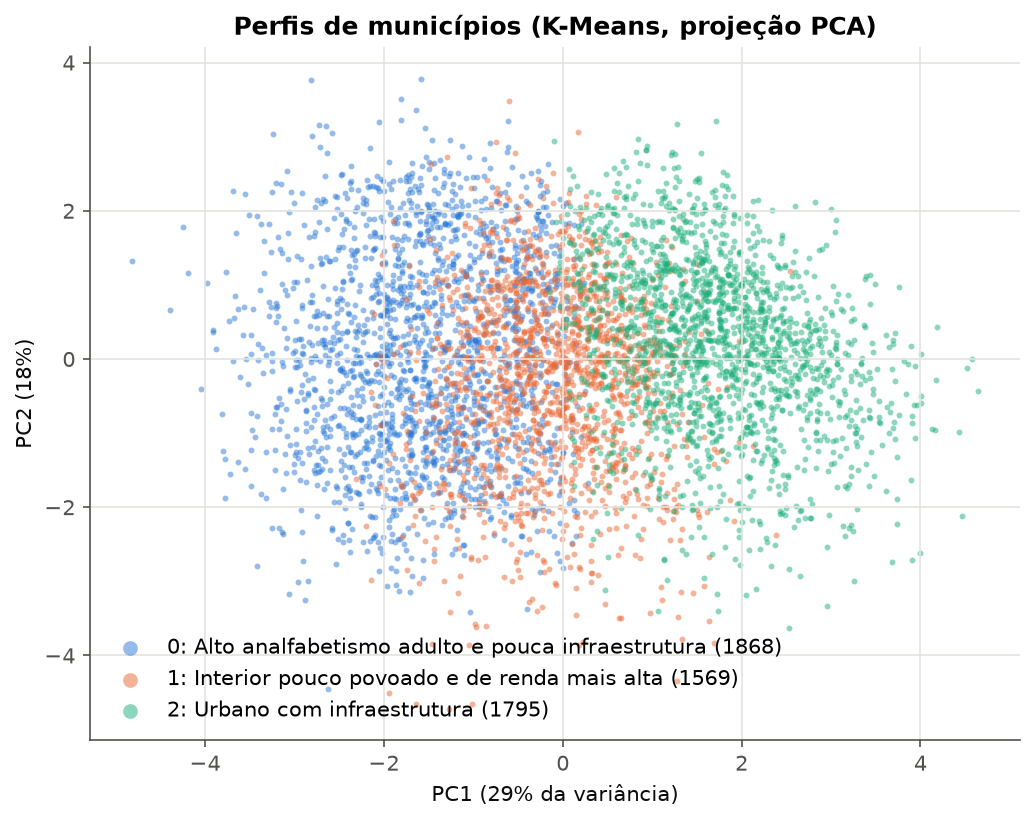

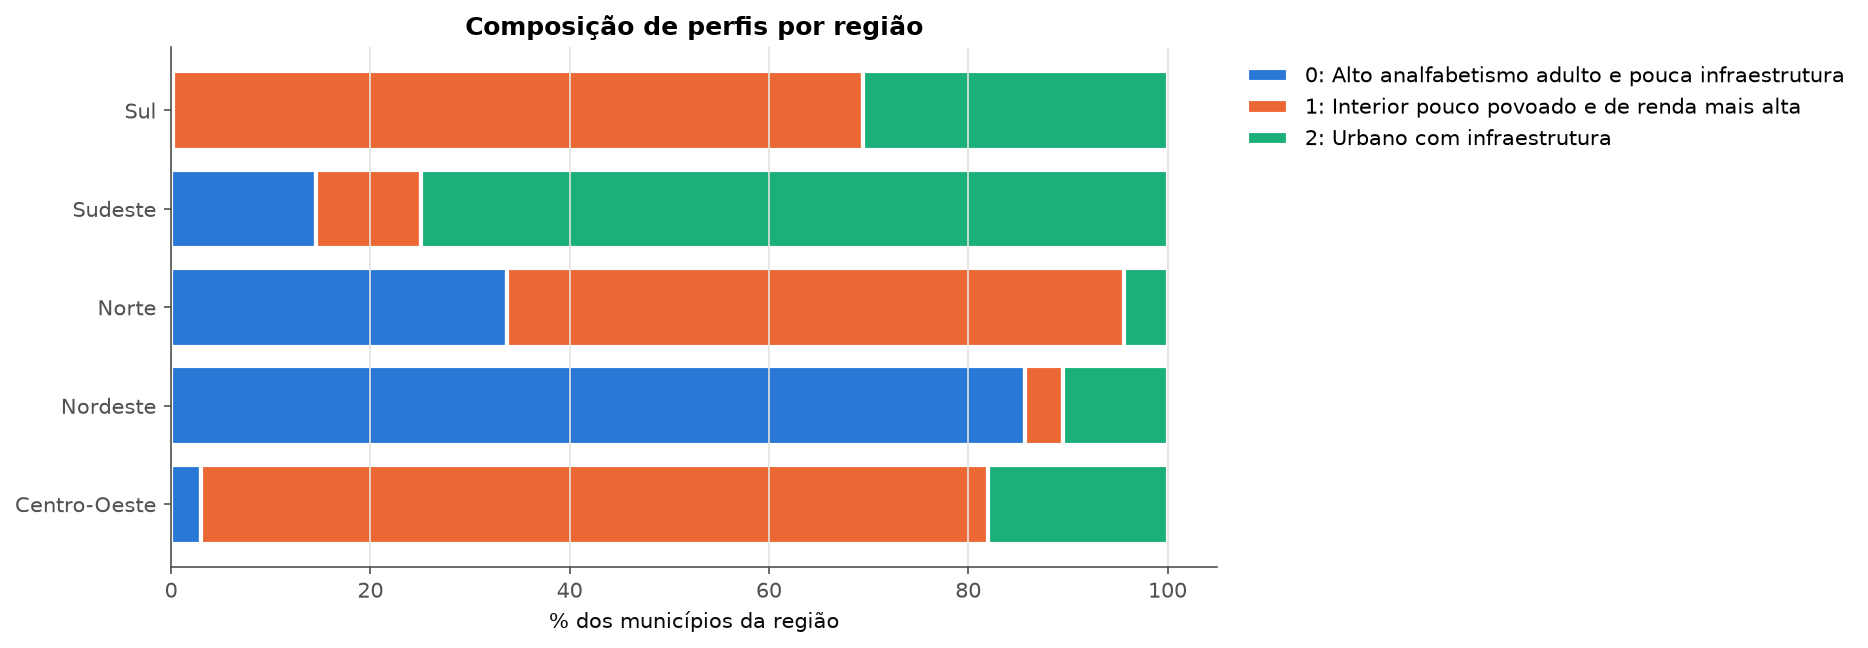

In [13]:
figura("cluster_pca", 650)
figura("cluster_por_regiao", 800)

In [14]:
clusters = pd.read_csv(C.DIR_REPORTS / "clusters_municipios.csv")
pd.crosstab(clusters["nome_regiao"], clusters["cluster"], normalize="index").mul(100).round(0)

cluster,0,1,2
nome_regiao,,,
Centro-Oeste,3.00,79.00,18.00
Nordeste,86.00,4.00,10.00
Norte,34.00,62.00,4.00
Sudeste,15.00,11.00,75.00
Sul,0.00,69.00,31.00


In [15]:
taxas = pd.read_csv(C.DIR_REPORTS / f"risco_municipios_{C.ANO_PROJECAO}.csv")[["id_municipio", f"taxa_{C.ANO_ALVO}"]]
clusters.merge(taxas, on="id_municipio").groupby("cluster")[f"taxa_{C.ANO_ALVO}"].describe(
    percentiles=[0.1, 0.5, 0.9])[["count", "10%", "50%", "90%"]]

,count,10%,50%,90%
cluster,,,,
0,"1,868.00",30.78,55.83,91.23
1,"1,569.00",39.99,66.70,87.04
2,"1,795.00",45.32,67.83,86.19


A silhueta ficou baixa para qualquer número de grupos. Isso quer dizer que os
municípios não se separam em grupos bem definidos; eles variam de forma contínua. Por
isso tratamos os grupos como perfis para orientar políticas, não como divisões
rígidas. Ficamos com três, que são fáceis de entender.

| Perfil | Onde aparece | O que chama atenção |
|---|---|---|
| 0 · Alto analfabetismo adulto e pouca infraestrutura | 86% do Nordeste, 34% do Norte | 21% dos adultos não sabem ler; menor taxa (56%), mas subindo (+3 pontos) |
| 1 · Interior pouco povoado e de renda mais alta | 79% do Centro-Oeste, 69% do Sul, 62% do Norte | maior PIB per capita, menor densidade e pior saneamento; taxa de 67%, mas parado (−1 ponto) |
| 2 · Urbano com infraestrutura | 75% do Sudeste | taxa parecida com a do perfil 1 (68%), e a que mais subiu (+4 pontos) |

Duas coisas que achamos importantes:

1. Renda não garante resultado. O perfil 1 tem três vezes o PIB per capita do perfil 0,
   só 11 pontos a mais de alfabetização, e foi o único que não melhorou. Parece um bom
   alvo para programas de alfabetização em redes pequenas e espalhadas do interior.
2. Dentro do perfil 0 há de tudo: os 10% melhores municípios passam de 90% e os 10%
   piores ficam abaixo de 31%, com contexto parecido. Os melhores podem servir de
   exemplo para os outros, como o Ceará fez com seus municípios.

## 5. Respondendo às perguntas do desafio

**Quais fatores mais impactam a alfabetização?** A qualidade da rede de ensino do
município. O que mais prevê o resultado de uma criança é como a rede foi no ano
anterior, tanto na alfabetização do 2º ano quanto no Ideb do 5º ano. Depois vem o
estado e a região, onde estão as políticas estaduais. Renda e alfabetização dos adultos
pesam pouco, e dentro das regiões a relação chega a ser negativa.

**Quais municípios apresentam maior risco?** O arquivo
`reports/risco_municipios_2025.csv` lista os 5.352 municípios com meta, ordenados pela
distância prevista até a meta de 2025, com a probabilidade e a faixa de risco. Cerca de
2.200 estão em risco alto ou muito alto, principalmente no AM, BA, PA, AP, AC e RO.

**Quais regiões possuem padrões semelhantes?** Encontramos três perfis que não seguem
exatamente as regiões do mapa: um ligado ao Nordeste, um ao interior pouco povoado do
Centro-Oeste, Sul e Norte, e um mais urbano, ligado ao Sudeste. E dentro de cada perfil
os resultados variam muito.

**Como prever municípios que podem não atingir metas futuras?** Prevendo a taxa de
alfabetização e comparando com a meta, considerando o erro do modelo. Em 2024 isso
acertou com AUC de 0,81 em municípios que o modelo nunca tinha visto, e funciona para
qualquer meta até 2030.

**Quais variáveis possuem maior influência nos modelos?** A taxa de alfabetização da
rede no ano anterior, o Ideb 2023 das escolas da rede, a nota média do município, a UF
e a mesorregião, e o tipo de rede (estadual ou municipal). Os detalhes estão no
notebook 03.